# Figure 3 — Regime-dependent ordering reversal within and across datasets
Decile curves: independent-half model score vs rep_cen decile for
K562 essential and GWPS (ordering reversal) + DAE baseline comparison.
Data: j22 fold-frozen + `j47_*_dae*.csv`.

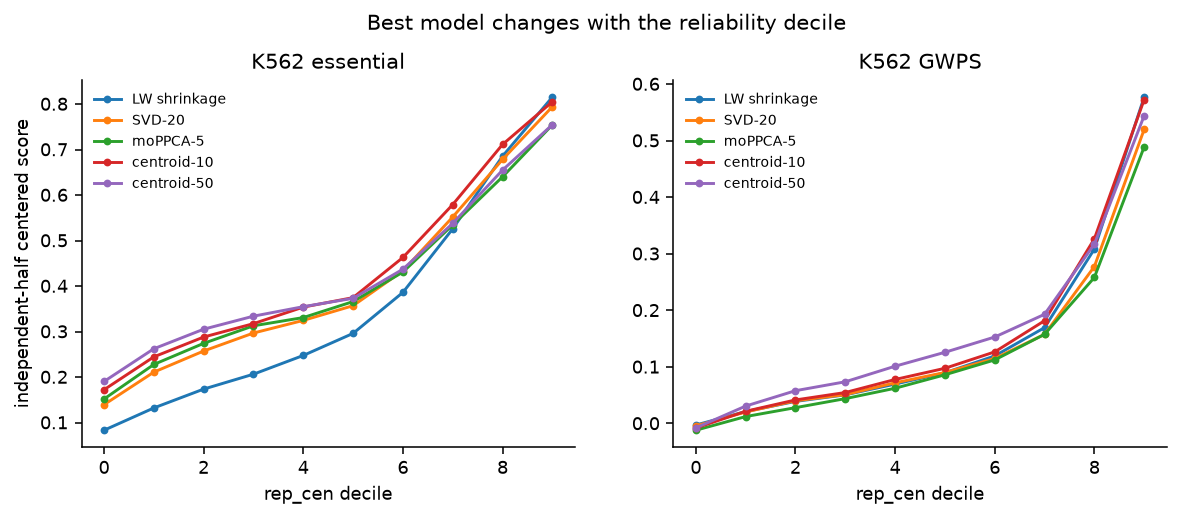

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RES = os.path.join("..", "..", "results")
FIG = os.path.join("..", "..", "figures")
os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 140, "savefig.dpi": 300,
                     "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False})
MODELS = ["lw", "svd20", "moppca5", "nn10", "nn50"]
MODEL_LABELS = {"lw": "LW shrinkage", "svd20": "SVD-20",
                "moppca5": "moPPCA-5", "nn10": "centroid-10",
                "nn50": "centroid-50"}
CONTEXTS = [
    ("K562 essential", "j22_k562_foldfrozen_centroid.csv"),
    ("K562 GWPS", "j22_k562_gwps_foldfrozen_centroid.csv"),
    ("Norman", "j49_norman_foldfrozen.csv"),
    ("RPE1", "j49_rpe1_foldfrozen.csv"),
    ("sci-Plex3", "j49_sciplex3.csv"),
]
def load_ctx(name, fname):
    df = pd.read_csv(os.path.join(RES, fname))
    df["context"] = name
    return df

def decile_curve(df, model):
    d = df.dropna(subset=["rep_cen", f"{model}_B_cen"]).copy()
    d["dec"] = pd.qcut(d["rep_cen"], 10, labels=False, duplicates="drop")
    return d.groupby("dec")[f"{model}_B_cen"].mean()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=False)
for ax, (cname, fname) in zip(axes, CONTEXTS[:2]):
    df = pd.read_csv(os.path.join(RES, fname))
    for m in MODELS:
        s = decile_curve(df, m)
        ax.plot(s.index, s.values, marker="o", ms=3, label=MODEL_LABELS[m])
    ax.set_xlabel("rep_cen decile")
    ax.set_title(cname)
    ax.legend(frameon=False, fontsize=7)
axes[0].set_ylabel("independent-half centered score")
fig.suptitle("Best model changes with the reliability decile", y=1.02)
fig.savefig(os.path.join(FIG, "fig3_decile_reversal.png"), bbox_inches="tight")
plt.show()


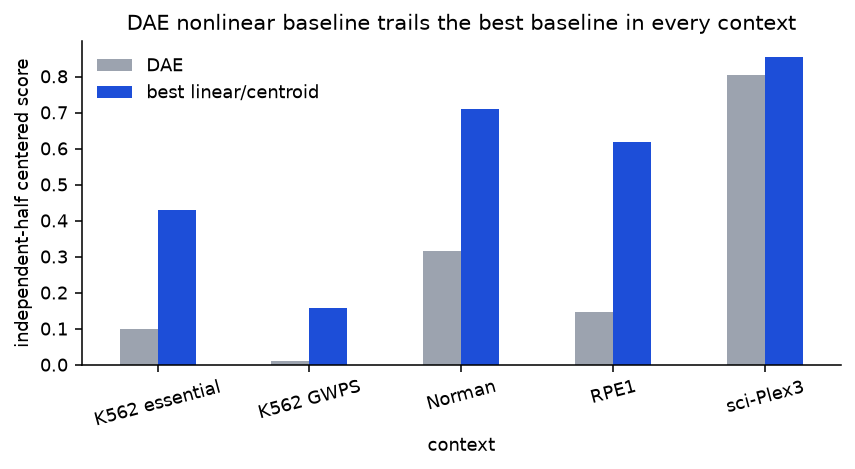

,DAE,best linear/centroid
context,,
K562 essential,0.099,0.431
K562 GWPS,0.010,0.159
Norman,0.317,0.709
RPE1,0.145,0.618
sci-Plex3,0.805,0.855


In [2]:

# ---- DAE vs baselines across contexts ----
dae_files = {
    "K562 essential": "j47_k562_dae_foldfrozen.csv",
    "K562 GWPS": "j47_gwps_dae_foldfrozen.csv",
    "Norman": "j47_norman_dae.csv",
    "RPE1": "j47_rpe1_dae.csv",
    "sci-Plex3": "j47_sciplex3_dae.csv",
}
rows = []
for cname, f in dae_files.items():
    p = os.path.join(RES, f)
    if not os.path.exists(p):
        continue
    d = pd.read_csv(p)
    bcols = [c for c in d.columns if c.endswith("_B_cen") and "dae" in c.lower()] or \
            [c for c in d.columns if c.endswith("B_cen")]
    # find dae column
    dae_col = next((c for c in d.columns if "dae" in c.lower() and c.endswith("B_cen")), None)
    base = load_ctx(cname, dict(CONTEXTS)[cname])
    best_lin = max(base[f"{m}_B_cen"].mean() for m in MODELS)
    rows.append({"context": cname,
                 "DAE": d[dae_col].mean() if dae_col else np.nan,
                 "best linear/centroid": best_lin})
t = pd.DataFrame(rows).set_index("context")
ax = t.plot.bar(figsize=(7.0, 3.0), color=["#9ca3af", "#1d4ed8"])
ax.set_ylabel("independent-half centered score")
ax.set_title("DAE nonlinear baseline trails the best baseline in every context")
ax.legend(frameon=False)
plt.xticks(rotation=15)
fig = ax.get_figure()
fig.savefig(os.path.join(FIG, "fig3b_dae_vs_baselines.png"), bbox_inches="tight")
plt.show()
t.round(3)
